# Books Sales and Ratings

I chose this dataset after considering a few options, including movies and wellbeing. Books have a mix of ratings, genres, prices and sales figures that can be compared.

**Main question:** how do book ratings, genres, prices and publishers relate to the sales figures in this dataset?

**Source:** [Books Sales and Ratings on Kaggle](https://www.kaggle.com/datasets/thedevastator/books-sales-and-ratings), shared by thedevastator. The description credits [Josh Murrey](https://data.world/josh-nbu). The CSV was downloaded on 21 October 2026.

The analysis uses Pandas for the data checks and calculations, and Matplotlib for all six charts. The code is followed by Markdown explaining the steps and results. The findings describe this dataset, rather than the whole book market.

## 1. Loading the data

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display

# Find the project folder from either the root or notebooks folder.
ROOT = Path.cwd()
if not (ROOT / "data/raw/manifest.json").exists():
    ROOT = ROOT.parent
if not (ROOT / "data/raw/manifest.json").exists():
    raise FileNotFoundError("Open this notebook from the project folder or notebooks folder.")

DATA_PATH = ROOT / "data/raw/Books_Data_Clean.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Run python scripts/download_data.py from the project folder first.")

manifest = json.loads((ROOT / "data/raw/manifest.json").read_text())
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == manifest["sha256"], "Check the dataset version."
raw = pd.read_csv(DATA_PATH)

FIGURES = ROOT / "reports/figures"
TABLES = ROOT / "reports/tables"
PROCESSED = ROOT / "data/processed"
for folder in [FIGURES, TABLES, PROCESSED]:
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
display(raw.head(3))

Rows: 1,070 | Columns: 15


,index,Publishing Year,Book Name,Author,language_code,Author_Rating,Book_average_rating,Book_ratings_count,genre,gross sales,publisher revenue,sale price,sales rank,Publisher,units sold
0,0,1975.0,Beowulf,"Unknown, Seamus Heaney",en-US,Novice,3.42,155903,genre fiction,34160.0,20496.0,4.88,1,HarperCollins Publishers,7000
1,1,1987.0,Batman: Year One,"Frank Miller, David Mazzucchelli, Richmond Lew...",eng,Intermediate,4.23,145267,genre fiction,12437.5,7462.5,1.99,2,HarperCollins Publishers,6250
2,2,2015.0,Go Set a Watchman,Harper Lee,eng,Novice,3.31,138669,genre fiction,47795.0,28677.0,8.69,3,"Amazon Digital Services, Inc.",5500


`read_csv()` loads the original file into a DataFrame called `raw`. The path checks let the notebook run from the main folder or the notebooks folder. The checksum checks that the CSV is the same version recorded in the project.

The file has **1,070 rows and 15 columns**. Each row is a book record. The first rows give an idea of the values, but they aren't enough to judge the whole dataset. The folders above hold the cleaned copy, summary tables and saved charts.

## 2. Initial checks

In [2]:
audit = pd.DataFrame({
    "column": [repr(name) for name in raw.columns],
    "type": raw.dtypes.astype(str).to_numpy(),
    "missing": raw.isna().sum().to_numpy(),
    "missing_percent": raw.isna().mean().mul(100).round(2).to_numpy(),
    "unique_values": raw.nunique().to_numpy(),
})
display(audit)
raw.info()
display(raw.describe(include="all").T)
print("Exact duplicates:", raw.duplicated().sum())
print("Duplicates without the index column:", raw.drop(columns="index").duplicated().sum())
audit.to_csv(TABLES / "initial_data_checks.csv", index=False)

,column,type,missing,missing_percent,unique_values
0,'index',int64,0,0.00,1070
1,'Publishing Year',float64,1,0.09,150
2,'Book Name',str,23,2.15,1045
3,'Author',str,0,0.00,735
4,'language_code',str,53,4.95,8
5,'Author_Rating',str,0,0.00,4
6,'Book_average_rating',float64,0,0.00,134
7,'Book_ratings_count',int64,0,0.00,1064
8,'genre',str,0,0.00,4
9,'gross sales',float64,0,0.00,831


<class 'pandas.DataFrame'>
RangeIndex: 1070 entries, 0 to 1069
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   index                1070 non-null   int64  
 1   Publishing Year      1069 non-null   float64
 2   Book Name            1047 non-null   str    
 3   Author               1070 non-null   str    
 4   language_code        1017 non-null   str    
 5   Author_Rating        1070 non-null   str    
 6   Book_average_rating  1070 non-null   float64
 7   Book_ratings_count   1070 non-null   int64  
 8   genre                1070 non-null   str    
 9   gross sales          1070 non-null   float64
 10  publisher revenue    1070 non-null   float64
 11  sale price           1070 non-null   float64
 12  sales rank           1070 non-null   int64  
 13  Publisher            1070 non-null   str    
 14  units sold           1070 non-null   int64  
dtypes: float64(5), int64(4), str(6)
memory usage: 125

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
index,1070.0,NaN,NaN,NaN,534.5,309.026698,0.0,267.25,534.5,801.75,1069.0
Publishing Year,1069.0,NaN,NaN,NaN,1971.377923,185.080257,-560.0,1985.0,2003.0,2010.0,2016.0
Book Name,1047,1045,The Awakening,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Author,1070,735,Stephen King,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
language_code,1017,8,eng,737,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Author_Rating,1070,4,Intermediate,625,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Book_average_rating,1070.0,NaN,NaN,NaN,4.007,0.247244,2.97,3.85,4.015,4.17,4.77
Book_ratings_count,1070.0,NaN,NaN,NaN,94909.913084,31513.242518,27308.0,70398.0,89309.0,113906.5,206792.0
genre,1070,4,genre fiction,822,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gross sales,1070.0,NaN,NaN,NaN,1856.622944,3936.92424,104.94,372.465,809.745,1487.9575,47795.0


Exact duplicates: 0
Duplicates without the index column: 0


`info()` shows column types and non-missing counts. `describe()` gives summary statistics; `.T` puts each original column on its own row. Some statistics don't apply to text columns, so the summary shows `NaN` for those entries.

The audit found **23 missing book names**, **53 missing language codes** and **1 missing publishing year**. There are **no duplicate rows**, including when the exported index is left out. `Publisher ` has a space at the end of its name.

The year column includes values as early as **−560**. Several titles also appear to have encoding problems. Neither issue should be fixed by guessing.

## 3. Cleaning

I kept all usable records rather than dropping a whole row just because its title or language was missing. Those fields aren't needed for the five main comparisons. The original CSV stays unchanged.

In [3]:
books = raw.copy()
books.columns = books.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
books = books.rename(columns={"index": "source_row"})

# Tidy spaces while keeping names and source categories.
text_columns = ["book_name", "author", "language_code", "author_rating", "genre", "publisher"]
space_changes = {}
for column in text_columns:
    before = books[column].astype("string")
    after = before.str.replace(r"\s+", " ", regex=True).str.strip().replace("", pd.NA)
    space_changes[column] = int(before.fillna("<missing>").ne(after.fillna("<missing>")).sum())
    books[column] = after

display(pd.Series(space_changes, name="rows_with_spacing_changes").to_frame())

,rows_with_spacing_changes
book_name,33
author,19
language_code,0
author_rating,0
genre,0
publisher,600


Column names now use lowercase words separated by underscores, so `gross sales` becomes `gross_sales`. The exported `index` is renamed `source_row` to keep a link to the original row; it isn't used as a measure.

Extra spaces were removed from **33 book names**, **19 author entries** and **600 publisher entries**. For example, the double space in Amazon's name became a single space. This changes formatting, rather than trying to correct titles or merge publishers.

In [4]:
numeric_columns = ["source_row", "publishing_year", "book_average_rating", "book_ratings_count",
                   "gross_sales", "publisher_revenue", "sale_price", "sales_rank", "units_sold"]
conversion_losses = {}
for column in numeric_columns:
    before = books[column].notna().sum()
    books[column] = pd.to_numeric(books[column], errors="coerce")
    conversion_losses[column] = int(before - books[column].notna().sum())

# Keep whole-number fields as nullable integers.
integer_columns = ["source_row", "publishing_year", "book_ratings_count", "sales_rank", "units_sold"]
for column in integer_columns:
    values = books[column].dropna()
    assert values.mod(1).eq(0).all(), f"Review non-integer values in {column}."
    books[column] = books[column].astype("Int64")

range_checks = pd.Series({
    "ratings outside 0 to 5": int((books.book_average_rating.notna() & ~books.book_average_rating.between(0, 5)).sum()),
    "negative sales or prices": int(books[["gross_sales", "publisher_revenue", "sale_price", "units_sold"]].lt(0).any(axis=1).sum()),
    "negative rating counts": int(books.book_ratings_count.lt(0).sum()),
    "non-positive sales ranks": int(books.sales_rank.le(0).sum()),
    "future publishing years": int(books.publishing_year.gt(2026).sum()),
})
assert range_checks.eq(0).all(), "Review invalid values before continuing."
assert books.source_row.is_unique, "Review the source row identifiers."

content_columns = [column for column in books.columns if column != "source_row"]
duplicates = int(books.duplicated(subset=content_columns).sum())
books = books.drop_duplicates(subset=content_columns).copy()
print("New missing values from numeric conversion:", sum(conversion_losses.values()))
print("Duplicate rows removed after tidying:", duplicates)
display(range_checks.to_frame("rows"))

New missing values from numeric conversion: 0
Duplicate rows removed after tidying: 0


,rows
ratings outside 0 to 5,0
negative sales or prices,0
negative rating counts,0
non-positive sales ranks,0
future publishing years,0


`to_numeric()` checks that numerical fields can be read as numbers. It created **no new missing values**. Whole-number fields use Pandas' nullable `Int64` type, which allows the missing publishing year to stay missing.

The range checks found **no invalid ratings, negative sales/prices, negative rating counts, non-positive sales ranks or future publishing years**. There were still **no duplicates** after tidying spaces, so **0 rows were removed**.

The year is kept as a number rather than converted to a date. Negative years could refer to ancient works, and publishing year isn't the year a sale happened.

In [5]:
# Keep original language codes and add a readable group.
language_map = {"eng": "English", "en-US": "English", "en-GB": "English", "en-CA": "English",
                "fre": "French", "spa": "Spanish", "ara": "Arabic", "nl": "Dutch"}
books["language_group"] = books.language_code.map(language_map).fillna("Unknown")
books["publishing_year_bce"] = books.publishing_year.lt(0).fillna(False)

# This is a review flag, not an automatic correction of titles.
books["possible_encoding_issue"] = books.book_name.str.contains(r"Ã|Â|Î|Ï|â€|á¼|�", na=False)

expected_gross = books.sale_price * books.units_sold.astype(float)
books["revenue_gap"] = books.gross_sales - expected_gross
books["sales_values_match"] = np.isclose(books.gross_sales, expected_gross, atol=0.01, rtol=0)

cleaning_counts = pd.Series({
    "rows before cleaning": len(raw),
    "rows after cleaning": len(books),
    "missing book names retained": int(books.book_name.isna().sum()),
    "unknown language groups": int(books.language_group.eq("Unknown").sum()),
    "missing publishing years retained": int(books.publishing_year.isna().sum()),
    "negative publishing years flagged": int(books.publishing_year_bce.sum()),
    "possible title encoding issues flagged": int(books.possible_encoding_issue.sum()),
    "sales values that match": int(books.sales_values_match.sum()),
    "sales values that do not match": int((~books.sales_values_match).sum()),
    "zero publisher revenues retained": int(books.publisher_revenue.eq(0).sum()),
})
display(cleaning_counts.to_frame("count"))
display(books.dtypes.astype(str).rename("cleaned_type").to_frame())

books.to_csv(PROCESSED / "books_cleaned.csv", index=False)
cleaning_counts.to_csv(TABLES / "cleaning_counts.csv", header=["count"], index_label="check")
print("Saved the cleaned copy to data/processed/books_cleaned.csv")

,count
rows before cleaning,1070
rows after cleaning,1070
missing book names retained,23
unknown language groups,53
missing publishing years retained,1
negative publishing years flagged,6
possible title encoding issues flagged,20
sales values that match,444
sales values that do not match,626
zero publisher revenues retained,372


,cleaned_type
source_row,Int64
publishing_year,Int64
book_name,string
author,string
language_code,string
author_rating,string
book_average_rating,float64
book_ratings_count,Int64
genre,string
gross_sales,float64


Saved the cleaned copy to data/processed/books_cleaned.csv


All **1,070 rows** remain. The cleaned table has **20 columns**, including five additional fields for grouping and quality checks.

- Missing book names, years and original language codes are kept as missing. Only the new `language_group` uses **Unknown** for the **53** missing language codes.
- **6 negative years** are flagged rather than deleted.
- A simple text pattern flags **20 possible title encoding issues**. This is a review aid, not a complete encoding check, and the titles aren't guessed or rewritten.
- `genre fiction` and `fiction` remain separate because the source does not clearly explain their distinction. Similar publisher names are also kept separate.
- `Author_Rating` contains labels such as Famous and Novice. It is treated as a category, despite the source description calling it numeric.
- **372 zero publisher revenues** are kept. A zero may be meaningful or may reflect a recording problem; there isn't enough evidence to replace it.

`np.isclose()` checks whether gross sales equal price × units sold within **0.01**, allowing for small rounding differences. Only **444 records match**; **626 don't**. This check identifies an inconsistency, but doesn't prove which field is wrong. Sales periods, discounts or definitions could differ. None of these numbers were overwritten.

The cleaned CSV is saved locally. The public repo contains the notebook, summary tables and figures, with a script to download the same raw CSV.

## 4. Analysis and charts

There are five main questions, plus a sixth check of the sales inconsistency. Each chart uses Matplotlib and is saved in `reports/figures/`. Medians are used for sales comparisons because a few large values can pull the mean upwards.

### Question 1: how are book ratings distributed?

,average_rating
count,1070.000000
mean,4.007000
std,0.247244
min,2.970000
25%,3.850000
50%,4.015000
75%,4.170000
max,4.770000


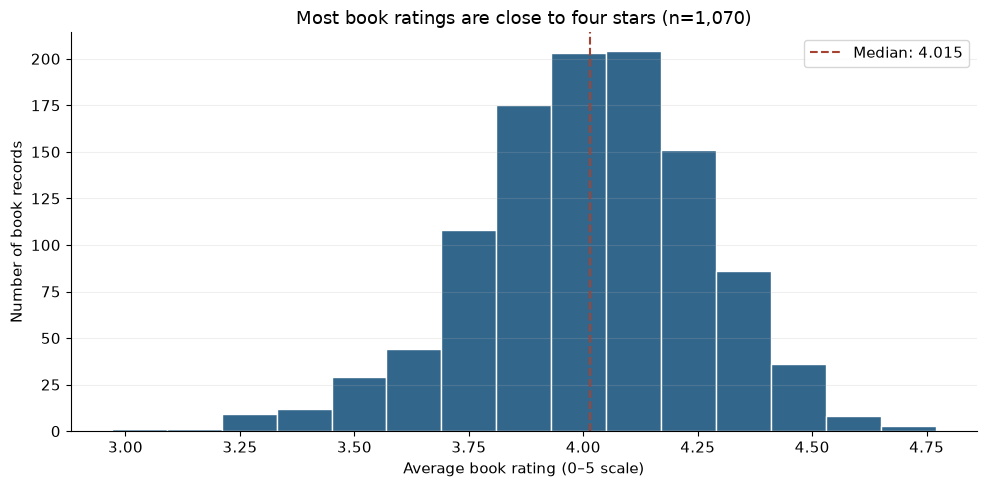

In [6]:
ratings = books.book_average_rating.dropna()
rating_summary = ratings.describe().rename("average_rating")
display(rating_summary.to_frame())
rating_summary.to_csv(TABLES / "ratings_summary.csv", index_label="statistic")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(ratings, bins=15, color="#32678B", edgecolor="white")
ax.set_title(f"Most book ratings are close to four stars (n={len(ratings):,})")
ax.set_xlabel("Average book rating (0–5 scale)")
ax.set_ylabel("Number of book records")
ax.axvline(ratings.median(), color="#A64232", linestyle="--", label=f"Median: {ratings.median():.3f}")
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "01_ratings_distribution.png", dpi=160)
plt.show()
plt.close(fig)

`describe()` summarises the ratings, and the histogram counts how many books fall into each rating interval. The dashed line marks the median. The horizontal axis measures ratings; the vertical axis counts book records.

The mean is **4.01**, and the median is **4.015**. The middle half of ratings falls between **3.85 and 4.17**, so most ratings are quite close together. The full range is **2.97 to 4.77**.

**Conclusion:** a high average rating is common in this dataset. Small rating differences alone may not be useful for deciding which books to promote; the sales relationship is checked in question 3.

### Question 2: which genres have higher typical sales?

,books,median_units,mean_units,matching_books,matching_median_units
genre,,,,,
children,15,5265.0,19874.53,3,249.0
fiction,62,4280.0,8800.94,20,256.0
nonfiction,171,4212.0,9559.99,57,365.0
genre fiction,822,3299.5,9581.31,364,455.5


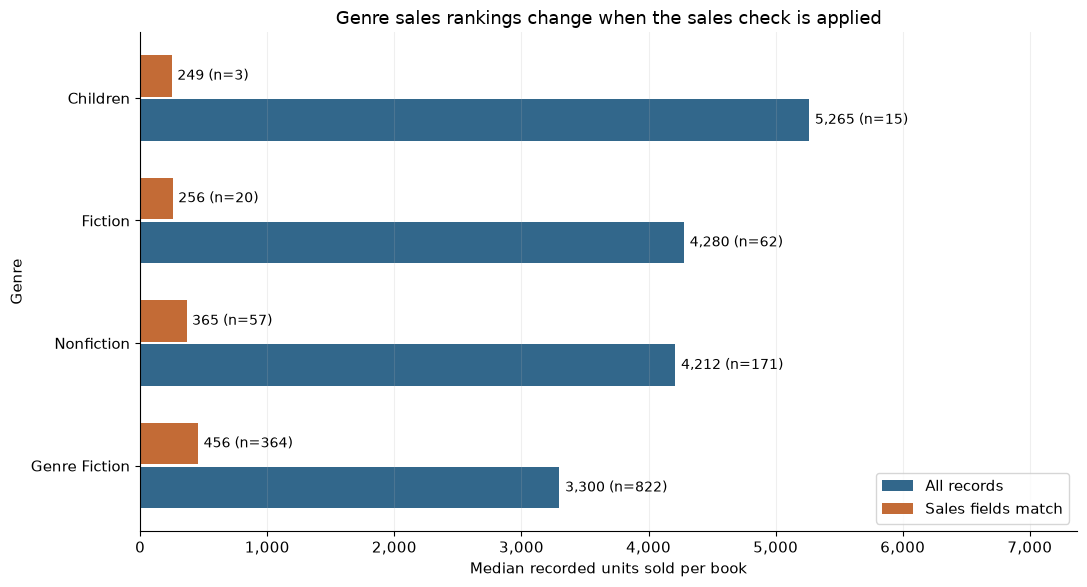

In [7]:
genre_sales = books.groupby("genre").agg(
    books=("source_row", "size"),
    median_units=("units_sold", "median"),
    mean_units=("units_sold", "mean"),
).sort_values("median_units", ascending=False)

# Compare the full sample with records whose sales fields match.
matching_books = books.loc[books.sales_values_match]
matching_genres = matching_books.groupby("genre").agg(
    matching_books=("source_row", "size"), matching_median_units=("units_sold", "median")
)
genre_sales = genre_sales.join(matching_genres)
display(genre_sales.round(2))
genre_sales.to_csv(TABLES / "genre_sales.csv", index_label="genre")

plot_data = genre_sales.sort_values("median_units")
y = np.arange(len(plot_data))
fig, ax = plt.subplots(figsize=(11, 6))
a = ax.barh(y - 0.18, plot_data.median_units, height=0.34, color="#32678B", label="All records")
b = ax.barh(y + 0.18, plot_data.matching_median_units, height=0.34, color="#C36B36", label="Sales fields match")
ax.bar_label(a, labels=[f"{value:,.0f} (n={int(n)})" for value, n in zip(plot_data.median_units, plot_data.books)], padding=4, fontsize=10)
ax.bar_label(b, labels=[f"{value:,.0f} (n={int(n)})" for value, n in zip(plot_data.matching_median_units, plot_data.matching_books)], padding=4, fontsize=10)
ax.set_yticks(y, plot_data.index.str.title())
ax.set_xlim(0, plot_data.median_units.max() * 1.4)
ax.set_xlabel("Median recorded units sold per book")
ax.set_ylabel("Genre")
ax.set_title("Genre sales rankings change when the sales check is applied")
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="lower right")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "02_sales_by_genre.png", dpi=160)
plt.show()
plt.close(fig)

`groupby()` calculates the median, mean and number of books for each genre. `join()` adds a second set of medians using only the records where gross sales match price × units sold. This is a sensitivity check: it asks whether the result changes when a different, clearly stated subset is used.

In the full sample, **children's books have the highest median recorded units sold (5,265)**, followed by fiction (**4,280**), nonfiction (**4,212**) and genre fiction (**3,299.5**). The children's group has only **15 books**, compared with **822** in genre fiction. Its much higher mean also shows that large observations affect the average.

The matching subset reverses the pattern: genre fiction has the highest median (**455.5**), while children has the lowest (**249**) based on just **3 books**. Matching records are not necessarily the correct records, and this subset is not a random sample.

**Recommendation:** don't increase spending on a genre based on these rankings alone. Check the sales definitions and collect more children's-book records first. The changed ranking is evidence that the initial result is fragile.

### Question 3: is there a relationship between ratings and sales?

,comparison,records,correlation
0,All records: Pearson,1070,-0.00852
1,All records: Spearman,1070,0.00054
2,Matching sales records: Spearman,444,0.03085


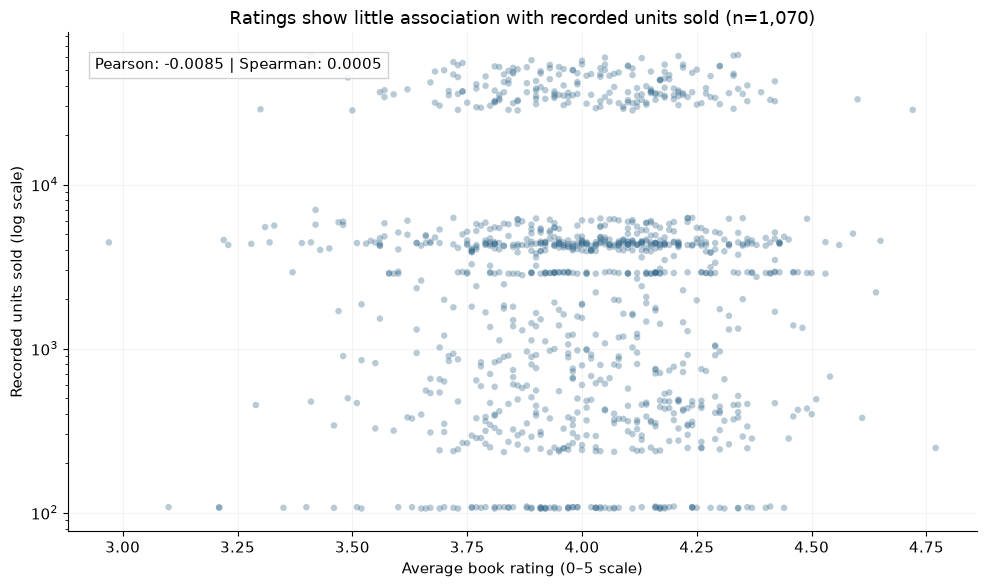

In [8]:
rating_sales = books[["book_average_rating", "units_sold"]].dropna()
pearson = rating_sales.book_average_rating.corr(rating_sales.units_sold)
# Correlation of ranks gives Spearman correlation without another package.
spearman = rating_sales.book_average_rating.rank().corr(rating_sales.units_sold.rank())
matching_spearman = matching_books.book_average_rating.rank().corr(matching_books.units_sold.rank())
correlations = pd.DataFrame({
    "comparison": ["All records: Pearson", "All records: Spearman", "Matching sales records: Spearman"],
    "records": [len(rating_sales), len(rating_sales), len(matching_books)],
    "correlation": [pearson, spearman, matching_spearman],
})
display(correlations.round(5))
correlations.to_csv(TABLES / "ratings_sales_correlations.csv", index=False)

# All sales are positive, so a log axis can show low and high values together.
assert rating_sales.units_sold.gt(0).all()
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(rating_sales.book_average_rating, rating_sales.units_sold.astype(float),
           alpha=0.35, s=22, color="#32678B", edgecolors="none")
ax.set_yscale("log")
ax.set_title(f"Ratings show little association with recorded units sold (n={len(rating_sales):,})")
ax.set_xlabel("Average book rating (0–5 scale)")
ax.set_ylabel("Recorded units sold (log scale)")
ax.text(0.03, 0.95, f"Pearson: {pearson:.4f} | Spearman: {spearman:.4f}", transform=ax.transAxes, va="top",
        bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "#CCCCCC"})
ax.grid(alpha=0.15)
fig.tight_layout()
fig.savefig(FIGURES / "03_ratings_and_sales.png", dpi=160)
plt.show()
plt.close(fig)

Each point is a book record. The log scale helps show a wide range of sales values on one chart; equal steps up the axis represent multiplication rather than equal increases in units. The correlation calculations still use the original units, not logged values.

Pearson correlation measures a straight-line relationship. Spearman compares the ranks of the values and is less affected by a few very large observations. Both range from −1 to 1; values near zero show little relationship of the kind being measured.

For all **1,070 records**, Pearson is **−0.0085** and Spearman is **0.0005**. These are both close to zero. The table also shows the matching-record sensitivity check.

**Recommendation:** don't use average rating by itself as a sales forecast or promotion rule. This dataset gives little evidence of a linear or monotonic relationship. That doesn't rule out other relationships or prove ratings never matter; the narrow range of ratings and the sales inconsistencies limit the conclusion.

### Question 4: how do prices vary by genre?

,books,median_price,lower_quartile,upper_quartile,min_price,max_price
genre,,,,,,
children,15,6.15,5.03,7.26,1.99,9.99
nonfiction,171,4.99,1.99,8.80,0.99,14.44
fiction,62,3.99,2.43,7.99,0.99,11.99
genre fiction,822,3.99,1.99,6.83,0.99,33.86


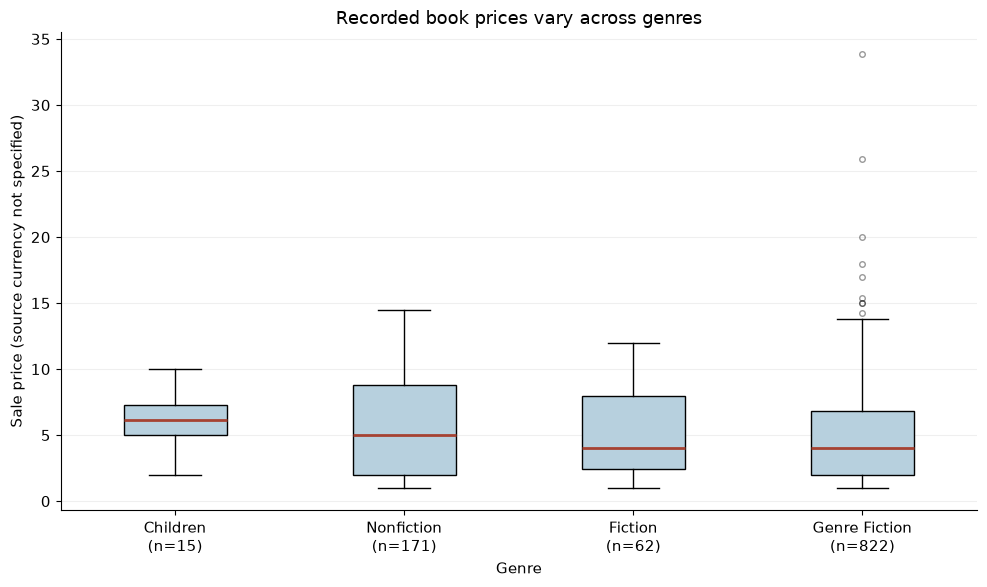

In [9]:
price_summary = books.groupby("genre").agg(
    books=("sale_price", "count"), median_price=("sale_price", "median"),
    lower_quartile=("sale_price", lambda x: x.quantile(0.25)),
    upper_quartile=("sale_price", lambda x: x.quantile(0.75)),
    min_price=("sale_price", "min"), max_price=("sale_price", "max"),
).sort_values("median_price", ascending=False)
display(price_summary.round(2))
price_summary.to_csv(TABLES / "prices_by_genre.csv", index_label="genre")

order = price_summary.index.tolist()
price_groups = [books.loc[books.genre.eq(genre), "sale_price"].dropna() for genre in order]
labels = [f"{genre.title()}\n(n={int(price_summary.loc[genre, 'books'])})" for genre in order]
fig, ax = plt.subplots(figsize=(10, 6))
boxes = ax.boxplot(price_groups, tick_labels=labels, patch_artist=True,
                   medianprops={"color": "#A64232", "linewidth": 2},
                   flierprops={"marker": "o", "markersize": 4, "alpha": 0.4})
for box in boxes["boxes"]:
    box.set_facecolor("#B7D0DE")
ax.set_title("Recorded book prices vary across genres")
ax.set_xlabel("Genre")
ax.set_ylabel("Sale price (source currency not specified)")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "04_prices_by_genre.png", dpi=160)
plt.show()
plt.close(fig)

The table compares typical prices and their spread. In the box plot, the line is the median and the box covers the middle half of prices. Whiskers reach the most extreme points within 1.5 times the box's height from its edges. Points beyond that are shown separately; they have not been removed from the data.

Children's books have the highest median recorded price (**6.15**), followed by nonfiction (**4.99**). Fiction and genre fiction both have a median of **3.99**. The source doesn't specify a currency, so the chart does not label the amounts as pounds or dollars.

**Recommendation:** use genre-specific price comparisons as a starting point for further research. Don't assume a higher price produces higher sales. Format, edition, market and currency information would be needed before recommending an actual price change.

### Question 5: how do sales compare across publishers?

,books,median_gross_sales,total_gross_sales
publisher,,,
Penguin Group (USA) LLC,108,1381.30,356362.47
HarperCollins Publishers,71,1230.24,214130.43
Random House LLC,120,1195.77,315975.37
Hachette Book Group,66,1102.21,229790.83
HarperCollins Publishing,4,1078.88,4718.01
Simon and Schuster Digital Sales Inc,56,991.24,78313.92
Macmillan,41,838.88,53927.06
HarperCollins Christian Publishing,4,692.86,3559.45
"Amazon Digital Services, Inc.",600,475.41,729809.01


Publishers included in the chart: 7 of 9


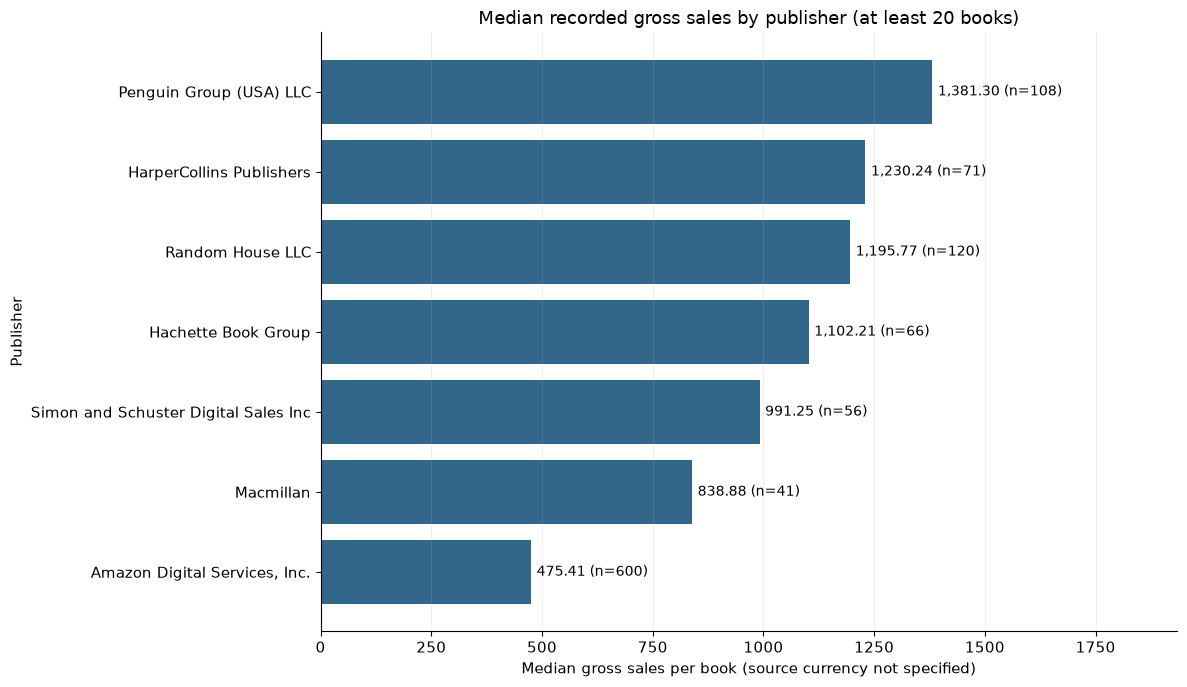

In [10]:
publisher_sales = books.groupby("publisher").agg(
    books=("source_row", "size"), median_gross_sales=("gross_sales", "median"),
    total_gross_sales=("gross_sales", "sum"),
)
# Use at least 20 records to avoid ranking publishers represented by only four books.
minimum_books = 20
publisher_comparison = publisher_sales.loc[publisher_sales.books.ge(minimum_books)].sort_values("median_gross_sales", ascending=False)
display(publisher_sales.sort_values("median_gross_sales", ascending=False).round(2))
publisher_sales.to_csv(TABLES / "publisher_sales.csv", index_label="publisher")
print(f"Publishers included in the chart: {len(publisher_comparison)} of {len(publisher_sales)}")

plot_data = publisher_comparison.sort_values("median_gross_sales")
fig, ax = plt.subplots(figsize=(12, 7))
bars = ax.barh(plot_data.index, plot_data.median_gross_sales, color="#32678B")
ax.bar_label(bars, labels=[f"{value:,.2f} (n={int(n)})" for value, n in zip(plot_data.median_gross_sales, plot_data.books)], padding=4, fontsize=10)
ax.set_xlim(0, plot_data.median_gross_sales.max() * 1.4)
ax.set_title("Median recorded gross sales by publisher (at least 20 books)")
ax.set_xlabel("Median gross sales per book (source currency not specified)")
ax.set_ylabel("Publisher")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "05_sales_by_publisher.png", dpi=160)
plt.show()
plt.close(fig)

`groupby()` calculates each publisher's book count, median gross sales and total gross sales. The chart includes publishers with at least **20 records**. This is a practical rule to leave out the two publishers represented by only four books; it is not a statistical guarantee of reliability. All nine publishers remain in the table.

Among the seven eligible publishers, **Penguin Group (USA) LLC** has the highest median recorded gross sales per book (**1,381.30**), followed by **HarperCollins Publishers (1,230.24)** and **Random House LLC (1,195.76)**.

**Amazon Digital Services, Inc.** has the largest recorded total (**729,809.01**) but the lowest median among these seven (**475.41**). It also has **600 records**, or **56.1%** of the dataset. This shows why total sales and typical sales per book tell different stories.

**Recommendation:** compare publisher medians together with book counts rather than selecting a publisher using totals alone. The catalogue mix and sales definitions need checking before treating these rankings as business performance measures.

### Question 6: how consistent are the sales fields?

,records,percent
Price × units matches gross sales,444,41.5
Price × units does not match,626,58.5


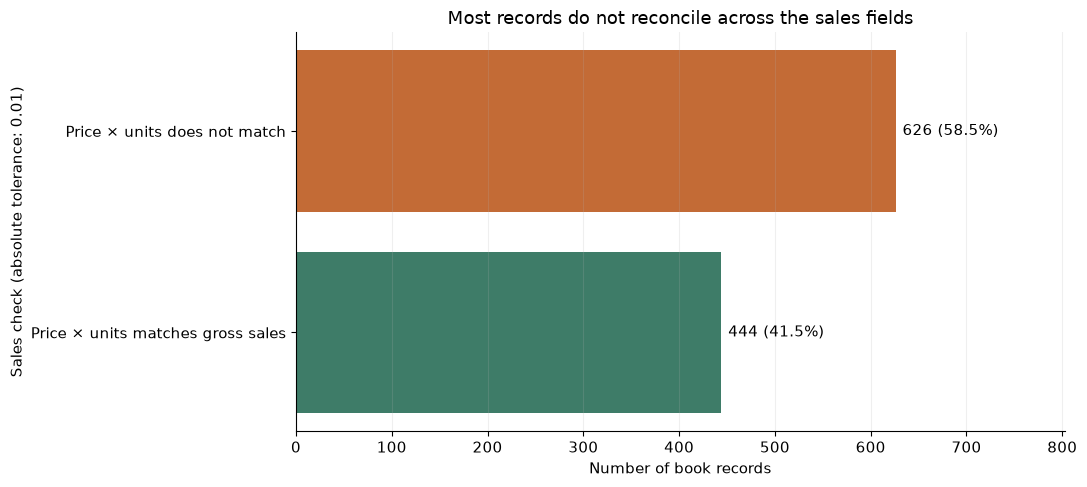

,zero_revenue_records
publisher,
"Amazon Digital Services, Inc.",372


In [11]:
quality_counts = pd.Series({
    "Price × units matches gross sales": int(books.sales_values_match.sum()),
    "Price × units does not match": int((~books.sales_values_match).sum()),
}, name="records")
quality_table = quality_counts.to_frame()
quality_table["percent"] = quality_table.records.div(len(books)).mul(100)
display(quality_table.round(2))
quality_table.to_csv(TABLES / "sales_quality.csv", index_label="check")

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(quality_table.index, quality_table.records, color=["#3E7C68", "#C36B36"])
ax.bar_label(bars, labels=[f"{int(n):,} ({p:.1f}%)" for n, p in zip(quality_table.records, quality_table.percent)], padding=5)
ax.set_xlim(0, len(books) * 0.75)
ax.set_title("Most records do not reconcile across the sales fields")
ax.set_xlabel("Number of book records")
ax.set_ylabel("Sales check (absolute tolerance: 0.01)")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES / "06_sales_data_check.png", dpi=160)
plt.show()
plt.close(fig)

revenue_zeros = books.loc[books.publisher_revenue.eq(0)].groupby("publisher").size().rename("zero_revenue_records")
display(revenue_zeros.to_frame())
revenue_zeros.to_csv(TABLES / "zero_publisher_revenue.csv", index_label="publisher")

There are **626 mismatches (58.5%)** and **444 matches (41.5%)** when price × units is compared with gross sales. The check allows an absolute difference of 0.01 for rounding. It assumes the three fields cover comparable transactions, which the source does not confirm.

There are also **372 records with zero publisher revenue (34.8%)**, all labelled Amazon Digital Services, Inc. These may have a separate explanation, but they should not be treated as proof that the publisher received no income.

**Recommendation:** checking definitions with the data owner is the first priority. Ask about currency, sales period, discounts, format, the source of units sold, and the meaning of zero publisher revenue. The changed genre rankings in question 2 show that this issue can affect the conclusions, not just the presentation of the data.